# 3D ink training from flattened 2D labels
The ink annotations begin as **2D images of flattened mesh segments**. Scan the
training segment's supervision mask, cover every supervised region with 512×512
seed rectangles, and project them into CT for a lightweight 3D U-Net. Its inputs
are **CT and geometric sheet coverage**; ink remains the target, never an input channel.

Train for complete epochs over the prepared dataset. A different PHercParis4
segment supplies validation. Predict overlapping chunks across its letter-scale
field and render their blended probabilities onto the flattened 2D sheet.


## Setup
Use a Python kernel with the package's `reader`, `labels` and `torch` dependencies,
Pillow, and the compiled extensions. The first run fetches public metadata, geometry
and CT chunks across the supervised training segment. Preparation and training
can take several minutes on CUDA, and longer on CPU. Prepared patches are cached
on disk and reused across epochs and notebook runs. No dependencies are installed.

The only imported example helper draws images; discovery, reading, the Dataset,
model, loss and validation are defined below. Set `VC_EXAMPLE_METADATA` to use a
local metadata snapshot.


In [1]:
from pathlib import Path
import os

import numpy as np
from _display import panel
from vc_reader import load
from vc_reader.reader import MemoryCache
CACHE = Path(os.environ.get('VC_EXAMPLE_CACHE', '/tmp/vc-reader-notebooks'))
METADATA = os.environ.get('VC_EXAMPLE_METADATA')  # optional local snapshot
options = dict(cache_dir=CACHE, cache_max_bytes=4 << 30, threads=8,
               memory_cache=MemoryCache(256 << 20))
catalog = load(METADATA) if METADATA else load()


In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device(os.environ.get('VC_EXAMPLE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu'))
print('Training device:', DEVICE)


Training device: cuda


## 1. Discover labels and hold out a second segment


In [3]:
paris = catalog.samples['PHercParis4']
available = list(paris.labels.filter(artifact_kind='ink-labels'))
print(f"{'segment':16} {'label set':12} {'source volume':16} {'paired Zarr images'}")
for label in available:
    print(f'{label.segment.id:16} {label.label_set:12} {label.volume.id:16} {len(label.images.filter(format="zarr"))}')
print('Available label sets:', sorted({label.label_set for label in available}))


segment          label set    source volume    paired Zarr images
20230702185753   20260918     20260411134726   1
20230929220926   20260918     20260411134726   1
20231007101619   20260918     20260411134726   1
20231012184424   20260918     20260411134726   1
20231016151002   20260918     20260411134726   1
20231031143852   20260918     20260411134726   1
20231106155351   20260918     20260411134726   1
20231210121321   20260918     20260411134726   1
Available label sets: ['20260918']


In [4]:
LABEL_SET = '20260918'
TRAIN_SEGMENT = '20230702185753'
VALID_SEGMENT = '20230929220926'
PATCH_YX = (512, 512)  # full-resolution label pixels, matching inference chunk context
SCAN_LEVEL = 3
SCAN_STEP = 2**SCAN_LEVEL
# Fixed letter-scale field on the held-out segment, independent of predictions.
VALIDATION_START_YX = (7984, 48896)
VALIDATION_SIZE_YX = (4096, 4096)
labels = {
    'train': paris.segments[TRAIN_SEGMENT].labels.ink(label_set=LABEL_SET),
    'validation': paris.segments[VALID_SEGMENT].labels.ink(label_set=LABEL_SET),
}
assert TRAIN_SEGMENT != VALID_SEGMENT

def supervised_tiles(support, target, full_resolution_shape, patch_yx, step, origin=(0, 0)):
    """Cover all scanned supervision, retaining negative-only and partial edge tiles."""
    if any(n <= 0 or n % step for n in patch_yx):
        raise ValueError('Patch dimensions must be positive multiples of scan spacing.')
    records = []
    h, w = (n//step for n in patch_yx)
    for y in range(0, support.shape[0], h):
        for x in range(0, support.shape[1], w):
            mask = support[y:y+h, x:x+w]
            count = int(mask.sum())
            if not count:
                continue
            start = (origin[0]+y*step, origin[1]+x*step)
            size = tuple(min(p, (extent-offset)*step, extent_full-s)
                         for p, extent, offset, extent_full, s in
                         zip(patch_yx, support.shape, (y, x), full_resolution_shape, start))
            if min(size) <= 0:
                raise ValueError('Scanned supervision lies outside the full-resolution label canvas.')
            records.append(dict(start=start, size=size, scan_count=count,
                scan_positive=int((target[y:y+h, x:x+w] & mask).sum())))
    return records

from vc_reader.reader import ZarrGroup
seeds, overviews = {}, {}
for split, label in labels.items():
    with ZarrGroup.open(label.source.storage.location, **options) as group:
        full_resolution_shape = group.level(0).shape
    origin = (0, 0) if split == 'train' else VALIDATION_START_YX
    with label.open_paired(image=label.surface_volumes.zarr(), level=SCAN_LEVEL,
                           layers=np.s_[0:0], backend='cpu', **options) as reader:
        size = reader.shape[-2:] if split == 'train' else tuple(n//SCAN_STEP for n in VALIDATION_SIZE_YX)
        y, x = (v//SCAN_STEP for v in origin)
        annotation = reader[y:y+size[0], x:x+size[1]].label
    support = annotation.valid[0] & (annotation.masks['supervision'][0] > 0)
    target = annotation.data[0] > 0
    seeds[split] = supervised_tiles(support, target, full_resolution_shape, PATCH_YX, SCAN_STEP, origin)
    if not seeds[split]:
        raise ValueError(f'No supervised tiles in {split}.')
    # Compact figures; release the full-canvas arrays after the scan.
    overviews[split] = (target[::4, ::4].copy(), support[::4, ::4].copy(), origin)
    print(split, 'segment', label.segment.id, 'label set', label.label_set, 'volume', label.volume.id)
    print('  ink:', label.source.storage.location)
    for companion in label.source.companions:
        print(f'  {companion.name}:', companion.source.storage.location)
    print(f'  {len(seeds[split])} supervised seeds; {int(support.sum()):,} supported level-{SCAN_LEVEL} pixels')
    assert sum(r['scan_count'] for r in seeds[split]) == int(support.sum())
del annotation, support, target


train segment 20230702185753 label set 20260918 volume 20260411134726
  ink: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20230702185753/ink-labels/2.4um-volume-20260411134726/20260918/inklabels.zarr/
  supervision: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20230702185753/ink-labels/2.4um-volume-20260411134726/20260918/supervision.zarr/
  772 supervised seeds; 2,060,815 supported level-3 pixels
validation segment 20230929220926 label set 20260918 volume 20260411134726
  ink: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20230929220926/ink-labels/2.4um-volume-20260411134726/20260918/inklabels.zarr/
  supervision: https://vesuvius-challenge-open-data.s3.us-east-1.amazonaws.com/PHercParis4/segments/20230929220926/ink-labels/2.4um-volume-20260411134726/20260918/supervision.zarr/
  43 supervised seeds; 122,056 supported level-3 pixels


## 2. Show where training and validation come from
The training grid covers every supervised tile on the selected segment at scan
level 3 (8× reduction). Selection uses supervision, including negative-only
regions; no ink-boundary coordinates or patch-count cap are used. Published
pyramid decimation can omit annotations finer than this scan resolution.
Validation covers the fixed 4096×4096 field on a separate segment.

Orange boxes show all selected 512×512 full-resolution seeds. White in the supervision
panel means a label is usable; black in an ink image alone does not establish
supervised background. A representative seed is chosen using supervised class
counts, without model predictions, for the projection illustration below.


train segment 20230702185753 | seeds: 772


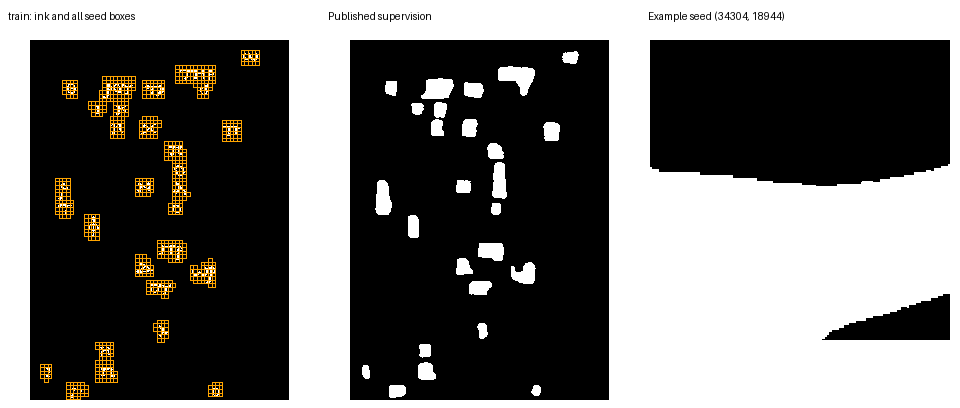

validation segment 20230929220926 | seeds: 43


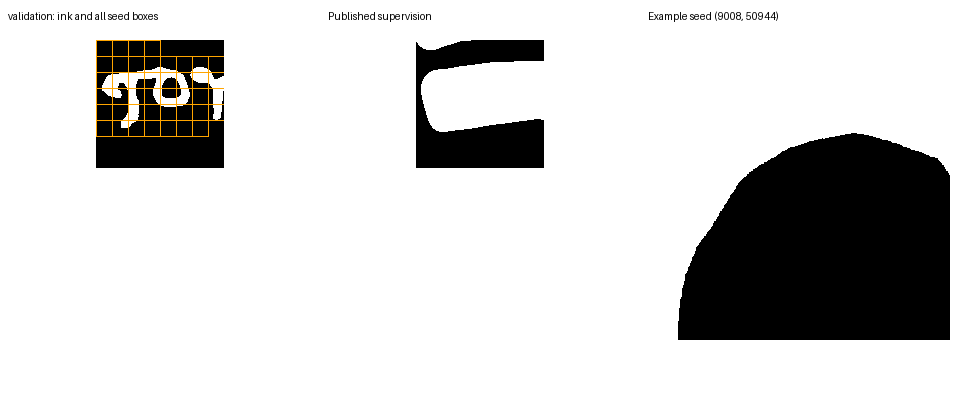

In [5]:
from PIL import Image, ImageDraw
from vc_reader.reader import ZarrGroup

def label_view(values, title, boxes=()):
    """Draw a compact label image, preserving aspect ratio and crop coordinates."""
    tile = Image.fromarray((np.asarray(values) > 0).astype(np.uint8)*255).convert('RGB')
    original_width, original_height = tile.size
    tile.thumbnail((300, 360), Image.Resampling.NEAREST)
    sx, sy = tile.width/original_width, tile.height/original_height
    draw = ImageDraw.Draw(tile)
    for (y, x), (h, w), caption, color in boxes:
        rect = (x*sx, y*sy, (x+w)*sx, (y+h)*sy)
        draw.rectangle(rect, outline=color, width=1)
        if caption:
            draw.text((rect[0]+3, rect[1]+3), caption, fill=color, stroke_width=1, stroke_fill='black')
    canvas = Image.new('RGB', (320, 408), 'white')
    canvas.paste(tile, ((320-tile.width)//2, 40))
    ImageDraw.Draw(canvas).text((8, 10), title, fill='black')
    return canvas

context_starts = {'validation': VALIDATION_START_YX}
examples = {}
for split, label in labels.items():
    target, support, origin = overviews[split]
    boxes = [((np.asarray(r['start'])-origin)/32, np.asarray(r['size'])/32, '', 'orange')
             for r in seeds[split]]
    representative = max(seeds[split], key=lambda r: min(r['scan_positive'], r['scan_count']-r['scan_positive']))
    with ZarrGroup.open(label.source.storage.location, **options) as group:
        y, x = representative['start']
        height, width = representative['size']
        flat = group.level(0)[y:y+height, x:x+width] > 0
    examples[split] = representative
    tiles = [label_view(target, f'{split}: ink and all seed boxes', boxes),
             label_view(support, 'Published supervision'),
             label_view(flat, f"Example seed {representative['start']}")]
    figure = Image.new('RGB', (960, 408), 'white')
    for i, tile in enumerate(tiles):
        figure.paste(tile, (320*i, 0))
    print(split, 'segment', label.segment.id, '| seeds:', len(seeds[split]))
    display(figure)


## 3. Make the registration and projection explicit
The labels are surface annotations registered to volume `20260411134726`.
The metadata links them to transformed `tifxyz` geometry. We explicitly declare
the full render-canvas pixel-center convention, label XY → UV = `(x+.5,y+.5)`;
it is separate from the volume affine. The selected published geometry bundles
have no optional `mask.tif`, so that lookup is disabled.

Project 512×512 full-resolution label pixels into CT level 2 (9.6 µm voxels). A 9.6 µm
label band gives the sheet finite thickness; 19.2 µm padding adds CT context.
The seed rectangle sets the crop bounds. Projection then uses the complete
registered sheet within that crop, including its padded margins. It does not
stop at the 2D seed boundary. Use batch size one for variable-sized crops.

The sheet channel is `coverage`, including both ink and non-ink sheet voxels.
It is independent of label availability, ink values and supervision. Loss support additionally
requires valid CT, nonzero supervision, and no categorical conflict. Uncovered
volume is context, not a negative ink label.

Preparation uses the model device and saves uint8 CT plus boolean sheet, ink and
support arrays to disk. One projected patch is resident at a time. Cache keys
include the source/registration, projection settings and backend; complete patch
files are reused on reruns. Unsupported projected seeds are reported and excluded.


In [6]:
from dataclasses import replace
import hashlib
import json

CT_LEVEL = 2
THICKNESS_UM = 9.6
PADDING_UM = 19.2
BATCH_SIZE = 1  # geometry produces variable ZYX crop shapes
prepared = {'train': [], 'validation': []}
as_tensor = torch.from_dlpack if DEVICE.type == 'cuda' else torch.from_numpy
for split, published in labels.items():
    surface = replace(published.source.registration.surface, tifxyz_mask=False)
    registration = replace(published.source.registration, surface=surface,
                           pixel_to_uv=((1, 0, .5), (0, 1, .5)), origin='explicit')
    ink = replace(published.source, id='user:notebook-ink', registration=registration)
    view = paris.with_source(ink, kind='label', volume=published.volume.id,
                             segment=published.segment.id)
    volume = view.volumes[published.volume.id]
    key = hashlib.sha256(repr((ink, volume.source, CT_LEVEL, THICKNESS_UM,
                               PADDING_UM, DEVICE.type, 'uint8-bool-v1')).encode()).hexdigest()[:24]
    patch_dir = CACHE / 'prepared-ink-3d' / key
    patch_dir.mkdir(parents=True, exist_ok=True)
    skipped = reused = 0
    with volume.open_aligned({'ink': view.labels[ink.id]}, level=CT_LEVEL,
                             backend=DEVICE.type, device=DEVICE.index or 0,
                             surface_output_bytes=64 << 20, **options) as reader:
        for index, seed in enumerate(seeds[split]):
            start, size = seed['start'], seed['size']
            path = patch_dir / ('-'.join(map(str, (*start, *size)))+'.npz')
            if not path.exists():
                sample = reader.project_surface(surface, start, size, label_target='ink',
                                                thickness_um=THICKNESS_UM, padding_um=PADDING_UM)
                annotation = sample['ink']
                sheet = as_tensor(annotation.masks['coverage']).bool()
                ct = as_tensor(sample.image.data)
                target = as_tensor(annotation.data) > 0
                support = (as_tensor(annotation.valid).bool() & as_tensor(sample.image.valid).bool()
                           & (as_tensor(annotation.masks['supervision']) > 0)
                           & ~as_tensor(annotation.masks['conflict']).bool())
                assert ct.dtype == torch.uint8
                assert not (as_tensor(annotation.valid).bool() & ~sheet).any().item()
                arrays = {k: v.cpu().numpy() for k, v in
                          dict(ct=ct, sheet=sheet, target=target, support=support).items()}
                # Atomic completion makes an interrupted preparation resumable.
                temporary = path.with_suffix('.tmp')
                with temporary.open('wb') as stream:
                    np.savez(stream, **arrays, count=int(support.sum()),
                             positive=int((target & support).sum()),
                             origin_zyx=sample.metadata['projection']['origin_zyx'])
                temporary.replace(path)
                del sample, annotation, sheet, ct, target, support, arrays
            else:
                reused += 1
            with np.load(path, allow_pickle=False) as patch:
                count, positive = int(patch['count']), int(patch['positive'])
            if count:
                prepared[split].append(dict(**seed, path=path, count=count, positive=positive))
            else:
                skipped += 1
            if (index+1) % 25 == 0 or index+1 == len(seeds[split]):
                print(f'{split}: {index+1}/{len(seeds[split])} projected/cached seeds', flush=True)
    if not prepared[split]:
        raise ValueError(f'No projected loss support in {split}.')
    print(f'{split}: {len(prepared[split])} usable patches, {reused} reused, {skipped} without projected support')
    print('  projected supported voxel observations:', sum(r['count'] for r in prepared[split]))
    print('  prepared patch cache:', patch_dir)


train: 25/772 projected/cached seeds
train: 50/772 projected/cached seeds
train: 75/772 projected/cached seeds
train: 100/772 projected/cached seeds
train: 125/772 projected/cached seeds
train: 150/772 projected/cached seeds
train: 175/772 projected/cached seeds
train: 200/772 projected/cached seeds
train: 225/772 projected/cached seeds
train: 250/772 projected/cached seeds
train: 275/772 projected/cached seeds
train: 300/772 projected/cached seeds
train: 325/772 projected/cached seeds
train: 350/772 projected/cached seeds
train: 375/772 projected/cached seeds
train: 400/772 projected/cached seeds
train: 425/772 projected/cached seeds
train: 450/772 projected/cached seeds
train: 475/772 projected/cached seeds
train: 500/772 projected/cached seeds
train: 525/772 projected/cached seeds
train: 550/772 projected/cached seeds
train: 575/772 projected/cached seeds
train: 600/772 projected/cached seeds
train: 625/772 projected/cached seeds
train: 650/772 projected/cached seeds
train: 675/772 

Train example seed: (6656, 16896) size: (512, 512)
The 3D panels include continuing sheet and labels outside that seed rectangle.


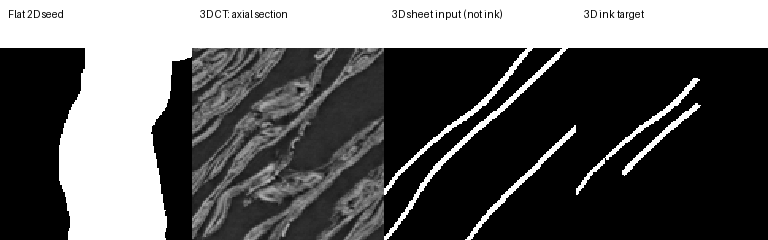

CT crop origin ZYX: [17061  4940  4047] ; local axial index: 49


In [7]:
example = max(prepared['train'], key=lambda r: min(r['positive'], r['count']-r['positive']))
with np.load(example['path'], allow_pickle=False) as data:
    ct, sheet, target = data['ct'][0], data['sheet'][0], data['target'][0]
    positive = (sheet & target).sum(axis=(1, 2))
    negative = (sheet & ~target).sum(axis=(1, 2))
    z = int(np.minimum(positive, negative).argmax())
    origin = data['origin_zyx']
with ZarrGroup.open(labels['train'].source.storage.location, **options) as group:
    y, x = example['start']
    height, width = example['size']
    flat = group.level(0)[y:y+height, x:x+width] > 0
print('Train example seed:', example['start'], 'size:', example['size'])
print('The 3D panels include continuing sheet and labels outside that seed rectangle.')
display(panel([('Flat 2D seed', flat), ('3D CT: axial section', ct[z].astype(np.float32)/255),
               ('3D sheet input (not ink)', sheet[z]), ('3D ink target', target[z])], size=192))
print('CT crop origin ZYX:', origin, '; local axial index:', z)
del ct, sheet, target


## 4. Build the Dataset and a two-channel 3D U-Net
Two downsampling stages and skip connections give the network context while
preserving small sheet features. GroupNorm works with batch size one. Normalize
only CT intensities; the second channel remains the binary geometric sheet mask.
Trilinear upsampling matches each skip's shape, including odd-sized crops.


In [8]:
class PatchDataset(Dataset):
    """Load one compact disk patch; convert only the current batch to float32."""
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        with np.load(self.records[index]['path'], allow_pickle=False) as patch:
            ct = torch.from_numpy(patch['ct']).float().div_(255)
            sheet = torch.from_numpy(patch['sheet']).float()
            return dict(image=torch.cat((ct, sheet), dim=0),
                        target=torch.from_numpy(patch['target']).float(),
                        support=torch.from_numpy(patch['support']))

train_data = PatchDataset(prepared['train'])
validation_data = PatchDataset(prepared['validation'])
# Readers close before training; each item loads a single prepared patch.
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          pin_memory=DEVICE.type == 'cuda',
                          generator=torch.Generator().manual_seed(7))
validation_loader = DataLoader(validation_data, batch_size=1, shuffle=False, num_workers=0,
                               pin_memory=DEVICE.type == 'cuda')
print('Train / validation patches:', len(train_data), len(validation_data))
print('Prepared files MiB:', sum(r['path'].stat().st_size for rows in prepared.values() for r in rows)/(1 << 20))


Train / validation patches: 772 43
Prepared files MiB: 5259.823600769043


In [9]:
import torch.nn.functional as F

class ConvBlock3d(nn.Module):
    def __init__(self, inputs, outputs):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv3d(inputs, outputs, 3, padding=1, bias=False),
            nn.GroupNorm(4, outputs), nn.SiLU(),
            nn.Conv3d(outputs, outputs, 3, padding=1, bias=False),
            nn.GroupNorm(4, outputs), nn.SiLU(),
        )

    def forward(self, x):
        return self.layers(x)

class InkUNet3d(nn.Module):
    def __init__(self, width=8):
        super().__init__()
        self.enc1 = ConvBlock3d(2, width)
        self.enc2 = ConvBlock3d(width, width*2)
        self.bottleneck = ConvBlock3d(width*2, width*4)
        self.dec2 = ConvBlock3d(width*6, width*2)
        self.dec1 = ConvBlock3d(width*3, width)
        self.head = nn.Conv3d(width, 1, 1)

    def forward(self, x):
        ct, sheet = x[:, :1], x[:, 1:2]
        mean = ct.mean(dim=(1, 2, 3, 4), keepdim=True)
        std = ct.std(dim=(1, 2, 3, 4), keepdim=True, correction=0).clamp_min(.02)
        e1 = self.enc1(torch.cat((((ct-mean)/std).clamp(-5, 5), sheet), dim=1))
        e2 = self.enc2(F.avg_pool3d(e1, 2))
        z = self.bottleneck(F.avg_pool3d(e2, 2))
        for block, skip in ((self.dec2, e2), (self.dec1, e1)):
            z = F.interpolate(z, size=skip.shape[-3:], mode='trilinear', align_corners=False)
            z = block(torch.cat((z, skip), dim=1))
        return self.head(z)

model = InkUNet3d().to(DEVICE)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')


Trainable parameters: 88,889


## 5. Train on every patch for three epochs
Each epoch visits every prepared training patch once in shuffled order. Class
weights use only training support. Matched random flips transform CT, sheet, ink
and support together on CPU or CUDA. Training uses masked BCE plus soft Dice.
Validation visits every prepared held-out patch after each epoch. A final pass
reports train metrics; every displayed prediction uses the final weights.

Voxel counts are observations across projected crops, whose padding can overlap;
they are not unique sheet-pixel counts. The stitched validation below scores each
supported surface pixel once. Compare Dice with the all-ink baseline.


In [10]:
import time

EPOCHS = 3
initial_parameters = [p.detach().clone() for p in model.parameters()]
positive = sum(r['positive'] for r in prepared['train'])
count = sum(r['count'] for r in prepared['train'])
pos_weight = torch.tensor((count-positive)/max(positive, 1), dtype=torch.float32, device=DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
print('Training-only positive weight:', float(pos_weight))
print(f'{EPOCHS} epochs × {len(train_loader)} batches = {EPOCHS*len(train_loader):,} optimizer steps')
print('Training all-ink Dice:', 2*positive/max(count+positive, 1))

def training_loss(logits, target, support):
    bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=pos_weight, reduction='none')
    probability = logits.sigmoid()
    weight = support.to(probability.dtype)
    dims = (1, 2, 3, 4)
    intersection = (probability*target*weight).sum(dim=dims)
    mass = ((probability+target)*weight).sum(dim=dims)
    dice = 1 - ((2*intersection+1)/(mass+1)).mean()
    return bce[support].mean() + .5*dice

@torch.no_grad()
def evaluate(loader):
    model.eval()
    loss_sum = count = intersection = predicted = positives = 0
    for batch in loader:
        image, target, support = (batch[k].to(DEVICE, non_blocking=True) for k in ('image', 'target', 'support'))
        logits = model(image)
        loss_sum += F.binary_cross_entropy_with_logits(logits, target, reduction='none')[support].sum().item()
        decision, truth = logits > 0, target > 0
        count += support.sum().item()
        intersection += (decision & truth & support).sum().item()
        predicted += (decision & support).sum().item()
        positives += (truth & support).sum().item()
    return dict(BCE=loss_sum/count, Dice=2*intersection/max(predicted+positives, 1),
                foreground=predicted/count, all_ink_Dice=2*positives/max(count+positives, 1))


print('Before training, held-out:', evaluate(validation_loader))
history = []
started = time.perf_counter()
for epoch in range(1, EPOCHS+1):
    model.train()
    total_loss = 0.
    seen = 0
    for batch_index, batch in enumerate(train_loader, 1):
        image, target, support = (batch[k].to(DEVICE, non_blocking=True) for k in ('image', 'target', 'support'))
        # Apply the same geometry to every aligned array on CPU or CUDA.
        axes = tuple(axis for axis in (-3, -2, -1) if torch.rand(()).item() < .5)
        if axes:
            image, target, support = (v.flip(axes) for v in (image, target, support))
        optimizer.zero_grad(set_to_none=True)
        loss = training_loss(model(image), target, support)
        assert torch.isfinite(loss), 'Non-finite training loss'
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.)
        optimizer.step()
        total_loss += loss.item()
        seen += image.shape[0]
        if batch_index % 100 == 0:
            print(f'Epoch {epoch}/{EPOCHS}: {batch_index}/{len(train_loader)} batches', flush=True)
    assert seen == len(train_data), 'Each epoch must use every training patch.'
    validation_metrics = evaluate(validation_loader)
    history.append(dict(epoch=epoch, patches=seen, loss=total_loss/len(train_loader), held_out=validation_metrics))
    print(history[-1], flush=True)
train_check = DataLoader(train_data, batch_size=1, shuffle=False, num_workers=0,
                         pin_memory=DEVICE.type == 'cuda')
print('Final training voxel metrics:', evaluate(train_check))
print(f'Training and validation: {time.perf_counter()-started:.1f} seconds')
assert any(not torch.equal(before, after) for before, after in zip(initial_parameters, model.parameters()))


Training-only positive weight: 2.9375269412994385
3 epochs × 772 batches = 2,316 optimizer steps
Training all-ink Dice: 0.40506107137372127
Before training, held-out: {'BCE': 0.6749814354699937, 'Dice': 0.16156711470677262, 'foreground': 0.11461117229349775, 'all_ink_Dice': 0.521499733162788}
Epoch 1/3: 100/772 batches
Epoch 1/3: 200/772 batches
Epoch 1/3: 300/772 batches
Epoch 1/3: 400/772 batches
Epoch 1/3: 500/772 batches
Epoch 1/3: 600/772 batches
Epoch 1/3: 700/772 batches
{'epoch': 1, 'patches': 772, 'loss': 1.3406254190546243, 'held_out': {'BCE': 0.629787529936929, 'Dice': 0.42614751190044164, 'foreground': 0.22553854139631457, 'all_ink_Dice': 0.521499733162788}}
Epoch 2/3: 100/772 batches
Epoch 2/3: 200/772 batches
Epoch 2/3: 300/772 batches
Epoch 2/3: 400/772 batches
Epoch 2/3: 500/772 batches
Epoch 2/3: 600/772 batches
Epoch 2/3: 700/772 batches
{'epoch': 2, 'patches': 772, 'loss': 1.3323119302024495, 'held_out': {'BCE': 0.6207879079714899, 'Dice': 0.481648776736957, 'foregro

## 6. Predict a letter-scale validation field and flatten the results
Use the same 4096×4096 full-resolution-pixel validation context shown above. Cover it
with 512×512 seed rectangles at stride 256. Each seed selects a 3D CT chunk;
the model receives only CT and geometric sheet coverage. Run all 225 chunks,
including unsupervised areas, with final weights and no augmentation.

Map the predicted 3D probabilities back onto the registered surface, sampling
at the label pixel centers. The crop origin and selected-volume affine in each
projection's metadata place its voxels correctly. Trilinear sampling uses
float32 coordinates relative to each crop. Output pixels are spaced eight
full-resolution label pixels apart, giving a 512×512 letter-scale image.

Blend overlapping predictions with tapered, nonzero edge weights and normalize
by their sum. This reduces seams while keeping boundary coverage. Only valid
geometry and CT contribute. Inference keeps one 3D chunk and small 2D accumulators
in memory; it does not allocate a letter-sized 3D prediction volume. The tensor
sampling and blending code runs on CPU or CUDA. Surface projection uses the
model device; CUDA arrays enter Torch directly through DLPack.

Score the final mosaic once per supervised pixel. These 2D metrics are separate
from the projected-crop voxel metrics above. The region is fixed from the validation
context, without inspecting model predictions or selecting a checkpoint.


In [11]:
from vc_reader import Affine
from vc_reader.surface import SurfaceGeometry


def overlap_starts(length, chunk, stride):
    """Cover both ends exactly, including a final non-stride-aligned window."""
    if not 0 < stride < chunk <= length:
        raise ValueError('Require 0 < stride < chunk <= region length.')
    positions = list(range(0, length-chunk+1, stride))
    if positions[-1] != length-chunk:
        positions.append(length-chunk)
    return positions


def blend_window(size, device):
    # Nonzero endpoints retain coverage at the outer boundary of the mosaic.
    axes = [torch.hann_window(n, periodic=False, dtype=torch.float32, device=device).clamp_min(.05)
            for n in size]
    return axes[0][:, None]*axes[1][None, :]


@torch.inference_mode()
def surface_plane(values, points_xyz, point_valid, point_base_xyz, origin_zyx):
    """Trilinearly sample CZYX tensors on a 2D geometry grid on CPU or CUDA."""
    # Subtract integer origins before float32 conversion to preserve local precision.
    delta = tuple(a-b for a, b in zip(point_base_xyz, reversed(origin_zyx)))
    local = torch.as_tensor(points_xyz, dtype=torch.float32, device=values.device)
    local = local + torch.tensor(delta, dtype=torch.float32, device=values.device)
    upper = torch.tensor(tuple(n-1 for n in reversed(values.shape[-3:])),
                         dtype=torch.float32, device=values.device)
    valid = torch.as_tensor(point_valid, dtype=torch.bool, device=values.device)
    valid = valid & torch.isfinite(local).all(dim=-1) & ((local >= 0) & (local <= upper)).all(dim=-1)
    grid = 2*local/upper.clamp_min(1)-1
    grid = torch.where(valid[..., None], grid, torch.zeros_like(grid))
    sampled = F.grid_sample(values[None], grid[None, None], mode='bilinear',
                            padding_mode='zeros', align_corners=True)[0, :, 0]
    return sampled, valid


In [12]:
# Infer the same letter-scale field shown in the validation label context above.
INFERENCE_SIZE_YX = VALIDATION_SIZE_YX  # full-resolution label pixels
INFERENCE_CHUNK_YX = PATCH_YX  # seed rectangle -> geometry-bounded 3D CT chunk
INFERENCE_STRIDE_YX = (256, 256)  # 50% overlap in the flattened canvas
DISPLAY_LEVEL = 3
DISPLAY_STEP = 2**DISPLAY_LEVEL
assert all(n % DISPLAY_STEP == 0 for n in (*INFERENCE_SIZE_YX, *INFERENCE_CHUNK_YX,
                                         *INFERENCE_STRIDE_YX))
validation_start = tuple(int(v) for v in context_starts['validation'])
y_starts = overlap_starts(INFERENCE_SIZE_YX[0], INFERENCE_CHUNK_YX[0], INFERENCE_STRIDE_YX[0])
x_starts = overlap_starts(INFERENCE_SIZE_YX[1], INFERENCE_CHUNK_YX[1], INFERENCE_STRIDE_YX[1])
output_yx = tuple(n//DISPLAY_STEP for n in INFERENCE_SIZE_YX)
tile_yx = tuple(n//DISPLAY_STEP for n in INFERENCE_CHUNK_YX)
weights = blend_window(tile_yx, DEVICE)
probability_sum = torch.zeros(output_yx, dtype=torch.float32, device=DEVICE)
ct_sum = torch.zeros_like(probability_sum)
weight_sum = torch.zeros_like(probability_sum)
contributors = torch.zeros(output_yx, dtype=torch.int32, device=DEVICE)

published = labels['validation']
surface = replace(published.source.registration.surface, tifxyz_mask=False)
registration = replace(published.source.registration, surface=surface,
                       pixel_to_uv=((1, 0, .5), (0, 1, .5)), origin='explicit')
ink = replace(published.source, id='user:notebook-validation-inference', registration=registration)
view = paris.with_source(ink, kind='label', volume=published.volume.id, segment=published.segment.id)
volume = view.volumes[published.volume.id]
assert surface.volume_id == volume.id, 'The prediction and geometry must use the same source volume.'

# Query only the displayed surface pixels, not every full-resolution UV pixel.
y, x = np.indices(tile_yx, dtype=np.float32)
uv = np.column_stack((x.ravel(), y.ravel()))*np.float32(DISPLAY_STEP)
physical_to_geometry = Affine.from_rows(tuple(
    tuple(1/surface.spacing_um[a] if a == b else 0 for b in range(3))+(0,)
    for a in range(3)))
# CUDA arrays enter Torch without a host round-trip.
as_tensor = torch.from_dlpack if DEVICE.type == 'cuda' else torch.from_numpy
model.eval()
started = time.perf_counter()
with volume.open_aligned({'ink': view.labels[ink.id]}, level=CT_LEVEL, backend=DEVICE.type, device=DEVICE.index or 0,
                         surface_output_bytes=64 << 20, **options) as reader, \
        SurfaceGeometry(surface, backend='cpu', **options) as geometry:
    for row, dy in enumerate(y_starts):
        for dx in x_starts:
            start = (validation_start[0]+dy, validation_start[1]+dx)
            sample = reader.project_surface(surface, start, INFERENCE_CHUNK_YX, label_target='ink',
                                            thickness_um=THICKNESS_UM, padding_um=PADDING_UM)
            sheet = as_tensor(sample['ink'].masks['coverage']).to(dtype=torch.float32)
            ct = as_tensor(sample.image.data).to(dtype=torch.float32)/255
            inputs = torch.cat((ct, sheet), dim=0)
            with torch.inference_mode():
                probability = model(inputs[None]).sigmoid()[0]
                fields = torch.cat((probability, inputs[:1],
                                    as_tensor(sample.image.valid).to(dtype=torch.float32)), dim=0)
                meta = sample.metadata['projection']
                reference_from_geometry = (Affine.from_rows(meta['array_to_level0']).inverse()
                                           @ surface.xyz_to_volume @ physical_to_geometry)
                # Match the declared label pixel centers: (x+.5, y+.5) in full-resolution UV.
                points, geometry_valid, point_base = geometry.geometry.sample(
                    uv, (0,), reference_from_geometry, (start[1]+.5, start[0]+.5, 0))
                values, mapped = surface_plane(fields, points[0].reshape(*tile_yx, 3),
                    geometry_valid[0].reshape(tile_yx), point_base, meta['origin_zyx'])
                # Require every CT voxel involved in interpolation to be valid.
                valid = mapped & (values[2] >= 1-1e-6)
                weight = weights*valid
                oy, ox = dy//DISPLAY_STEP, dx//DISPLAY_STEP
                region = np.s_[oy:oy+tile_yx[0], ox:ox+tile_yx[1]]
                probability_sum[region] += values[0]*weight
                ct_sum[region] += values[1]*weight
                weight_sum[region] += weight
                contributors[region] += valid.to(torch.int32)
        print(f'Inference row {row+1}/{len(y_starts)} ({(row+1)*len(x_starts)} chunks)', flush=True)

covered = weight_sum > 0
stitched_probability = (probability_sum/weight_sum.clamp_min(1e-8)).cpu().numpy()
stitched_ct = (ct_sum/weight_sum.clamp_min(1e-8)).cpu().numpy()
covered = covered.cpu().numpy()
contributors = contributors.cpu().numpy()
print(f'{len(y_starts)*len(x_starts)} overlapping chunks in {time.perf_counter()-started:.1f}s; '
      f'rendered coverage {covered.mean():.1%}; maximum contributions {int(contributors.max())}')

# Labels are used only for scoring/display; they never mask the prediction or select chunks.
with published.open_paired(image=published.surface_volumes.zarr(), level=DISPLAY_LEVEL,
                           layers=np.s_[0:0], backend='cpu', **options) as reader:
    y, x = (v//DISPLAY_STEP for v in validation_start)
    annotation = reader[y:y+output_yx[0], x:x+output_yx[1]].label
flat_target = annotation.data[0] > 0
flat_support = annotation.valid[0] & (annotation.masks['supervision'][0] > 0) & covered
if not flat_support.any():
    raise ValueError('No supervised rendered pixels in the validation field.')
decision = stitched_probability > .5
intersection = int((decision & flat_target & flat_support).sum())
predicted = int((decision & flat_support).sum())
positives = int((flat_target & flat_support).sum())
count = int(flat_support.sum())
print('Stitched 2D validation:', dict(Dice=2*intersection/max(predicted+positives, 1),
      all_ink_Dice=2*positives/max(count+positives, 1), supported_pixels=count,
      supervised_coverage=count/flat_support.size))


Inference row 1/15 (15 chunks)
Inference row 2/15 (30 chunks)
Inference row 3/15 (45 chunks)
Inference row 4/15 (60 chunks)
Inference row 5/15 (75 chunks)
Inference row 6/15 (90 chunks)
Inference row 7/15 (105 chunks)
Inference row 8/15 (120 chunks)
Inference row 9/15 (135 chunks)
Inference row 10/15 (150 chunks)
Inference row 11/15 (165 chunks)
Inference row 12/15 (180 chunks)
Inference row 13/15 (195 chunks)
Inference row 14/15 (210 chunks)
Inference row 15/15 (225 chunks)
225 overlapping chunks in 132.3s; rendered coverage 100.0%; maximum contributions 4
Stitched 2D validation: {'Dice': 0.20603099416295245, 'all_ink_Dice': 0.5244056506259331, 'supported_pixels': 122056, 'supervised_coverage': 0.465606689453125}


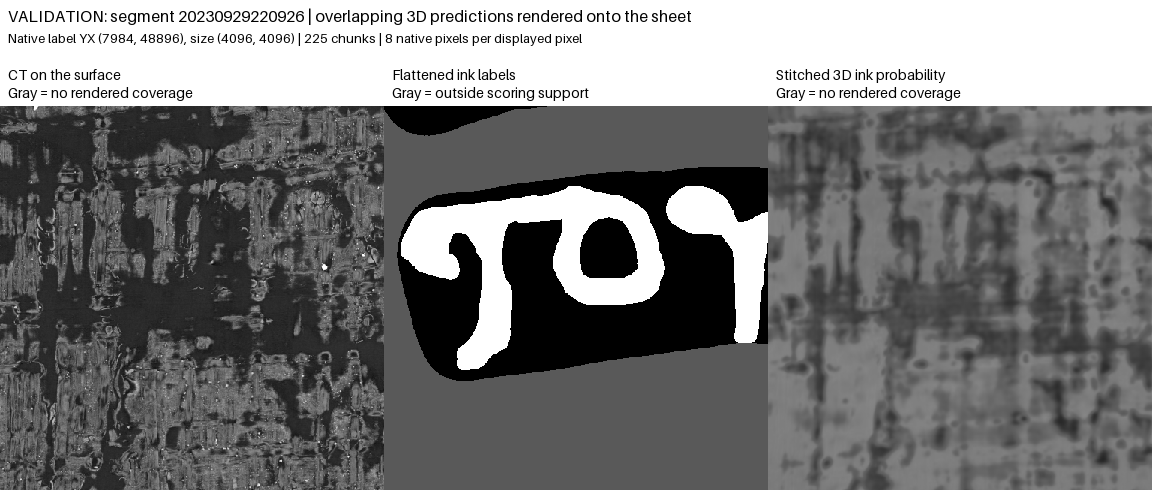

In [13]:
from PIL import ImageFont

unknown = np.float32(.35)
figure_tiles = panel([
    ('CT on the surface\nGray = no rendered coverage', np.where(covered, stitched_ct, unknown)),
    ('Flattened ink labels\nGray = outside scoring support', np.where(flat_support, flat_target, unknown)),
    ('Stitched 3D ink probability\nGray = no rendered coverage', np.where(covered, stitched_probability, unknown)),
], size=384, font_size=14)
figure = Image.new('RGB', (figure_tiles.width, figure_tiles.height+58), 'white')
figure.paste(figure_tiles, (0, 58))
draw = ImageDraw.Draw(figure)
draw.text((8, 6), f'VALIDATION: segment {VALID_SEGMENT} | overlapping 3D predictions rendered onto the sheet',
          fill='black', font=ImageFont.load_default(size=16))
draw.text((8, 30), f'Full-resolution label YX {validation_start}, size {INFERENCE_SIZE_YX} | '
          f'{len(y_starts)*len(x_starts)} chunks | {DISPLAY_STEP} full-resolution pixels per displayed pixel',
          fill='black', font=ImageFont.load_default(size=13))
display(figure)


## Interpreting the result
The training grid uses all supervision found at scan level 3 on the chosen
PHercParis4 segment, with larger 3D context and complete epochs. Change `EPOCHS`
to train longer. Change `TRAIN_SEGMENT` to explore a different source while
keeping `VALID_SEGMENT` separate. The split holds out a segment ID; a larger
experiment should also check whether segments overlap on the physical sheet.

The final surface view tests whether predictions form complete letters. Its
separate 2D score and all-ink baseline are more useful for that question than
scores on overlapping projected voxels. This short run is not a benchmark.

Prepared uint8/bool patches remain in the printed disk cache for reuse; the
Dataset holds only paths and counts. Delete that cache directory to rebuild
projections after changing the reader implementation. Source chunk caches and
model activations have separate memory budgets. Readers close after preparation
and after the stitched surface render.
